____
__Universidad Tecnológica Nacional, Buenos Aires__<br/>
__Ingeniería Industrial__<br/>
__Cátedra de Ciencia de Datos - Curso I5521 - Turno jueves noche__<br/>
__Trabajo Práctico Final: Bank Subscription - Análisis exploratorio de datos__<br/>
__Elaborado por: Grupo 7__
____

## Objetivo

El banco busca predecir qué clientes se suscribirán a una campaña de marketing (variable `Subscription`). Este notebook desarrolla el análisis exploratorio (EDA) del dataset, que contiene 45.211 clientes y 17 variables. El objetivo es conocer la calidad de los datos, definir su limpieza e identificar qué variables se asocian con la suscripción, como base para la etapa de modelado.

## Importamos las librerías necesarias

In [1]:
import math

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew

## Cargamos el dataset

In [2]:
df= pd.read_csv("bank_subscription.csv",delimiter=";")
df.head()


,Age,Job,Marital Status,Education,Credit,Balance (euros),Housing Loan,Personal Loan,Contact,Last Contact Day,Last Contact Month,Last Contact Duration,Campaign,Pdays,Previous,Poutcome,Subscription
0,58.0,NaN,NaN,NaN,no,2143.0,yes,NaN,unknown,5,may,261.0,1,-1.0,0,unknown,0
1,44.0,technician,single,secondary,no,NaN,yes,no,unknown,5,may,151.0,1,-1.0,0,unknown,0
2,33.0,entrepreneur,NaN,secondary,no,2.0,yes,yes,unknown,5,may,76.0,1,NaN,0,unknown,0
3,47.0,NaN,married,unknown,no,1506.0,NaN,no,unknown,5,may,92.0,1,-1.0,0,unknown,0
4,33.0,unknown,single,unknown,NaN,1.0,no,no,unknown,5,may,NaN,1,NaN,0,unknown,0


## Determinamos la cantidad de filas y columnas

In [3]:
filas = np.shape(df)[0]
columnas = np.shape(df)[1]
print(f"Filas: {filas}")
print(f"Columnas: {columnas}")
df.info()

Filas: 45211
Columnas: 17
<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Age                    40238 non-null  float64
 1   Job                    40238 non-null  str    
 2   Marital Status         40238 non-null  str    
 3   Education              40238 non-null  str    
 4   Credit                 40238 non-null  str    
 5   Balance (euros)        40238 non-null  float64
 6   Housing Loan           37525 non-null  str    
 7   Personal Loan          37525 non-null  str    
 8   Contact                45211 non-null  str    
 9   Last Contact Day       45211 non-null  int64  
 10  Last Contact Month     45211 non-null  str    
 11  Last Contact Duration  37525 non-null  float64
 12  Campaign               45211 non-null  int64  
 13  Pdays                  37525 non-null  float64
 14  Previous               45211 non-null  

## Estadística descriptiva

Con `.describe()` obtenemos un primer resumen de las variables numéricas: cantidad de valores no nulos, media, desvío estándar, mínimo, cuartiles y máximo.

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,40238.0,40.929768,10.631666,18.0,33.0,39.0,48.00,95.0
Balance (euros),40238.0,1367.154257,3079.452512,-8019.0,72.0,448.0,1425.75,102127.0
Last Contact Day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.00,31.0
Last Contact Duration,37525.0,258.511446,257.827942,0.0,103.0,180.0,319.00,4918.0
Campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.00,63.0
Pdays,37525.0,40.020546,99.728432,-1.0,-1.0,-1.0,-1.00,871.0
Previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.00,275.0
Subscription,45211.0,0.116985,0.321406,0.0,0.0,0.0,0.00,1.0


Del resumen surgen algunas observaciones que retomamos más adelante:

- **Balance (euros)** va de -8.019 € a 102.127 €, con una media (1.367 €) que triplica a la mediana (448 €): la distribución es muy asimétrica. Además, hay saldos negativos, que corresponden a cuentas en descubierto.
- **Campaign** tiene una mediana de 2 llamadas, pero llega a 63.
- **Previous** vale 0 hasta el percentil 75 (la mayoría de los clientes nunca fue contactado antes), pero su máximo es 275.
- **Pdays** vale -1 hasta el percentil 75. Ese valor es un código ("sin contacto previo"), no una cantidad de días, por lo que su media y su desvío no tienen una interpretación directa.

## Duplicados

Verificamos si hay registros duplicados.

In [5]:
print(f"Filas duplicadas: {df.duplicated().sum()}")
print(f"Filas duplicadas sin considerar Last Contact Duration: {df.drop(columns=['Last Contact Duration']).duplicated().sum()}")

Filas duplicadas: 0


Filas duplicadas sin considerar Last Contact Duration: 8


El dataset original no tiene registros duplicados. Al eliminar `Last Contact Duration` (ver más abajo), 8 filas pasan a coincidir con otras. Como el dataset no tiene un identificador de cliente y esas filas eran distintas en origen, las interpretamos como clientes diferentes con el mismo perfil y las conservamos.

### Eliminación de `Last Contact Duration`

La variable `Last Contact Duration` registra la duración, en segundos, de la última llamada realizada al cliente. El problema es que este dato solo se conoce una vez terminada la llamada, es decir, en el mismo momento en que se conoce si el cliente se suscribió o no. Si el objetivo del modelo es predecir qué clientes tienen mayor probabilidad de suscribirse *antes* de contactarlos, incluir esta variable implicaría usar información del futuro, lo que se conoce como *data leakage*. Además, su relación con el target es en parte trivial: una llamada muy corta, o de cero segundos, implica casi con certeza que el cliente no se suscribió. Un modelo entrenado con esta variable mostraría un desempeño artificialmente alto que no podría replicarse en la práctica. Por este motivo, decidimos eliminarla del análisis. La propia documentación del dataset recomienda descartarla cuando se busca un modelo predictivo realista.

In [6]:
df = df.drop(columns=["Last Contact Duration"])

# Copia sin imputar: la usamos para describir las distribuciones con los valores observados
df_raw = df.copy()

## Chequeamos nulos

In [7]:
nulos = pd.DataFrame({
    "nulos": df.isnull().sum(),
    "porcentaje": (df.isnull().mean() * 100).round(1),
}).sort_values("nulos", ascending=False)
nulos

,nulos,porcentaje
Housing Loan,7686,17.0
Personal Loan,7686,17.0
Pdays,7686,17.0
Age,4973,11.0
Education,4973,11.0
Marital Status,4973,11.0
Balance (euros),4973,11.0
Job,4973,11.0
Credit,4973,11.0
Contact,0,0.0


Vemos que hay 6 columnas con 4.973 nulos (11,0%) y otras tres con 7.686 (17,0%). Queda pendiente definir una estrategia de imputación. Antes de hacerlo, verificamos si los nulos siguen algún patrón.

### Patrón de los nulos

Que varias columnas tengan exactamente la misma cantidad de nulos sugiere que podrían estar en las mismas filas. Verificamos tres cosas:

1. Cuántas filas tienen al menos un nulo, es decir, cuántas perderíamos si las elimináramos.
2. Si los nulos de cada grupo de columnas coinciden en las mismas filas.
3. Si la tasa de suscripción cambia cuando el dato falta, lo que indicaría que los faltantes no son aleatorios.

In [8]:
mapa_nulos = df.isnull()
grupo_11 = ["Age", "Job", "Marital Status", "Education", "Credit", "Balance (euros)"]
grupo_17 = ["Housing Loan", "Personal Loan", "Pdays"]

filas_con_nulos = mapa_nulos.any(axis=1)
print(f"Filas con al menos un nulo: {filas_con_nulos.sum():,} ({filas_con_nulos.mean():.1%})")
print(f"Filas con las 6 columnas del grupo del 11% nulas a la vez: {mapa_nulos[grupo_11].all(axis=1).sum()}")
print(f"Filas con las 3 columnas del grupo del 17% nulas a la vez: {mapa_nulos[grupo_17].all(axis=1).sum()}")

# Tasa de suscripción según si el dato falta o no
cols_nulos = grupo_11 + grupo_17
tasa_nulos = pd.DataFrame({
    "tasa si falta": [df.loc[mapa_nulos[c], "Subscription"].mean() for c in cols_nulos],
    "tasa si no falta": [df.loc[~mapa_nulos[c], "Subscription"].mean() for c in cols_nulos],
}, index=cols_nulos)
(tasa_nulos * 100).round(1)

Filas con al menos un nulo: 32,427 (71.7%)
Filas con las 6 columnas del grupo del 11% nulas a la vez: 0
Filas con las 3 columnas del grupo del 17% nulas a la vez: 226


,tasa si falta,tasa si no falta
Age,11.0,11.8
Job,11.2,11.8
Marital Status,11.7,11.7
Education,12.8,11.6
Credit,11.8,11.7
Balance (euros),12.1,11.6
Housing Loan,11.7,11.7
Personal Loan,11.6,11.7
Pdays,12.2,11.6


In [9]:
# Pdays y Previous: ¿Pdays = -1 coincide siempre con Previous = 0 cuando Pdays está informado?
informado = df["Pdays"].notna()
coincide = ((df.loc[informado, "Pdays"] == -1) == (df.loc[informado, "Previous"] == 0)).mean()
print(f"Pdays = -1 coincide con Previous = 0 en el {coincide:.1%} de las filas con Pdays informado")
print(f"Nulos de Pdays con Previous = 0: {(~informado & (df['Previous'] == 0)).sum():,} de {(~informado).sum():,}")

Pdays = -1 coincide con Previous = 0 en el 100.0% de las filas con Pdays informado
Nulos de Pdays con Previous = 0: 6,269 de 7,686


**Conclusiones sobre los nulos:**

- **Eliminar filas no es una opción:** el 71,7% de las filas tiene al menos un nulo, por lo que descartarlas implicaría perder casi tres cuartas partes del dataset. Por eso imputamos.
- **Los nulos están dispersos:** a pesar de compartir la misma cantidad, los nulos de cada grupo no coinciden en las mismas filas. Cada columna tiene sus faltantes en registros distintos.
- **Los faltantes parecen aleatorios:** la tasa de suscripción es prácticamente la misma cuando el dato falta y cuando no (en todos los casos, entre el 11,0% y el 12,8%, en línea con la tasa general de 11,7%). No hay indicios de que el hecho de que falte un dato esté asociado a la suscripción, lo que respalda imputar con medidas simples como la mediana o la moda.
- **Pdays y Previous son consistentes entre sí:** cuando `Pdays` está informado, vale -1 exactamente cuando `Previous` es 0. Usamos esta relación para imputar `Pdays`.

Para definir la estrategia de imputación de cada variable, hacemos un breve análisis sobre los valores que toma cada una.

In [10]:
for col in df.columns:
    print(f"{col} ({df[col].nunique(dropna=False)} valores únicos)")
    print(df[col].unique())
    # print("-" * 40)

Age (78 valores únicos)
[58. 44. 33. 47. 35. 28. 42. 43. 41. 29. 53. 57. 51. 45. 60. 56. 32. 25.
 40. nan 52. 36. 49. 59. 37. 50. 54. 55. 48. 24. 38. 46. 30. 39. 34. 31.
 23. 26. 61. 22. 27. 21. 20. 66. 62. 83. 75. 67. 70. 65. 68. 64. 72. 71.
 19. 76. 69. 85. 63. 90. 82. 73. 74. 78. 80. 94. 79. 77. 95. 81. 18. 89.
 84. 86. 87. 92. 93. 88.]
Job (13 valores únicos)
<ArrowStringArray>
[            nan,    'technician',  'entrepreneur',       'unknown',
    'management',       'retired',        'admin.',      'services',
   'blue-collar', 'self-employed',    'unemployed',     'housemaid',
       'student']
Length: 13, dtype: str
Marital Status (4 valores únicos)
<ArrowStringArray>
[nan, 'single', 'married', 'divorced']
Length: 4, dtype: str
Education (5 valores únicos)
<ArrowStringArray>
[nan, 'secondary', 'unknown', 'tertiary', 'primary']
Length: 5, dtype: str
Credit (3 valores únicos)
<ArrowStringArray>
['no', nan, 'yes']
Length: 3, dtype: str
Balance (euros) (6868 valores únicos)
[2.143

Notamos que:

- `Age` es numérica. En función de la dispersión, convendrá imputar con media o mediana.
- `Job` es categórica. Una de sus categorías es `unknown`, se le asigna ese valor a los nulos.
- `Marital Status` es categórica con solo tres categorías.
- `Education` es categórica y también contempla una categoría `unknown`.
- `Credit` es binaria.
- `Balance (euros)` es continua, misma conclusión que `Age`.
- `Housing Loan` y `Personal Loan` son binarias.
- `Pdays` es continua.

Tomamos las binarias (más `Marital Status`, que es categórica con tres categorías) y hacemos un count plot para ver cómo se distribuyen los valores.

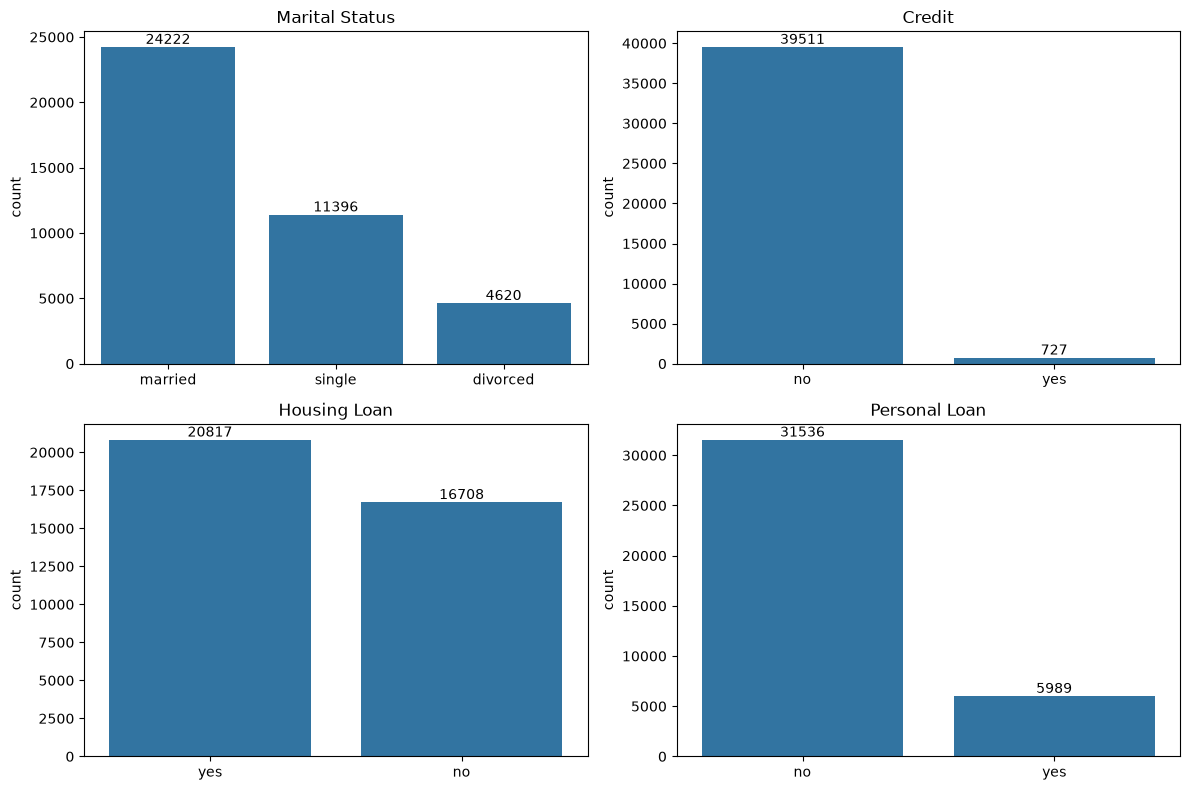

In [11]:
cols = ["Marital Status", "Credit", "Housing Loan", "Personal Loan"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flatten(), cols):
    sns.countplot(data=df, x=col, ax=ax, order=df[col].value_counts().index)
    ax.set_title(col)
    ax.set_xlabel("")
    for container in ax.containers:
        ax.bar_label(container)

plt.tight_layout()
plt.show()

### Variables binarias y categóricas: estrategia de imputación

**Credit y Personal Loan:** en ambas variables, la gran mayoría de los registros corresponde a `no`. Ante esta distribución tan desbalanceada, imputamos los valores faltantes con la moda, ya que es la opción con mayor probabilidad de acierto.

**Housing Loan:** la distribución entre `yes` y `no` es prácticamente equilibrada, por lo que imputar con la moda introduciría un error considerable. Optamos por agrupar los faltantes en una nueva categoría, `unknown`.

**Marital Status:** si bien la categoría dominante no es tan marcada como en `Credit` o `Personal Loan`, `married` sigue siendo claramente la más frecuente. Por eso, también imputamos con la moda.

**Job y Education:** ambas variables ya contemplan una categoría `unknown`, por lo que asignamos ese valor a los faltantes.

In [12]:
# Moda: Credit, Personal Loan, Marital Status
for col in ["Credit", "Personal Loan", "Marital Status"]:
    df[col] = df[col].fillna(df[col].mode()[0])

# Categoría unknown: Housing Loan, Job, Education
for col in ["Housing Loan", "Job", "Education"]:
    df[col] = df[col].fillna("unknown")

# Verificación
df[["Credit", "Personal Loan", "Marital Status", "Housing Loan", "Job", "Education"]].isnull().sum()

Credit            0
Personal Loan     0
Marital Status    0
Housing Loan      0
Job               0
Education         0
dtype: int64

Para determinar la estrategia de imputación de variables continuas, hacemos un boxplot para determinar la dispersión de su distribución.

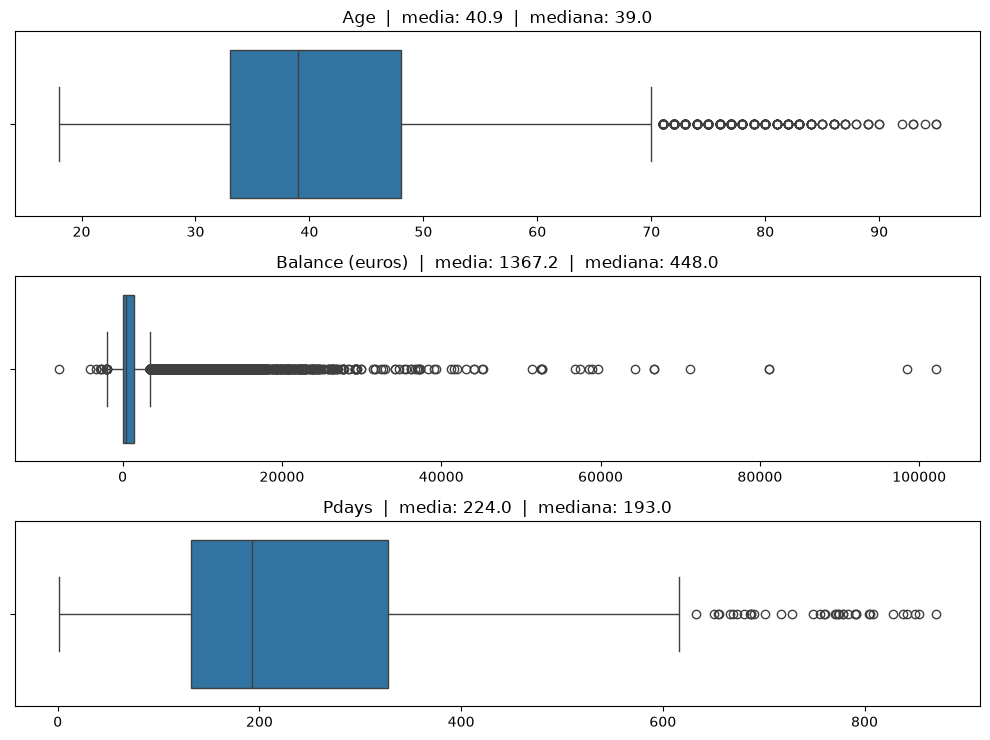

In [13]:
continuas_nulos = ["Age", "Balance (euros)", "Pdays"]

fig, axes = plt.subplots(len(continuas_nulos), 1, figsize=(10, 2.5 * len(continuas_nulos)))

for ax, col in zip(axes, continuas_nulos):
    datos = df.loc[df["Pdays"] != -1, col] if col == "Pdays" else df[col]
    sns.boxplot(x=datos, ax=ax)
    ax.set_title(f"{col}  |  media: {datos.mean():.1f}  |  mediana: {datos.median():.1f}")
    ax.set_xlabel("")

plt.tight_layout()
plt.show()

### Variables continuas: estrategia de imputación

**Age y Balance (euros):** ambas distribuciones presentan colas largas hacia la derecha y una cantidad considerable de outliers, especialmente `Balance (euros)`, cuya media casi triplica a la mediana. Para evitar que los valores extremos distorsionen la imputación, completamos los faltantes con la mediana, que es robusta ante este tipo de distribuciones.

**Pdays:** en esta variable, el valor `-1` indica que el cliente no fue contactado en campañas anteriores, por lo que la imputación debe respetar ese significado. Aplicamos dos criterios:

- Si `Previous` es 0, el cliente nunca fue contactado, por lo que imputamos `-1`. Como verificamos, en los registros informados esta relación se cumple en el 100% de los casos. Este criterio cubre 6.269 de los 7.686 nulos.
- En el resto de los casos, imputamos con la mediana de `Pdays` calculada solo sobre los clientes contactados previamente (excluyendo los `-1`).

In [14]:
# --- Imputación de variables continuas ---

# Age y Balance: mediana
for col in ["Age", "Balance (euros)"]:
    df[col] = df[col].fillna(df[col].median())

# Pdays (1): si nunca fue contactado (Previous == 0), imputamos -1
mask_nuevo = df["Pdays"].isna() & (df["Previous"] == 0)
df.loc[mask_nuevo, "Pdays"] = -1

# Pdays (2): para el resto, mediana de los clientes contactados previamente
mediana_pdays = df.loc[df["Pdays"] != -1, "Pdays"].median()
df["Pdays"] = df["Pdays"].fillna(mediana_pdays)

# Verificación
df[["Age", "Balance (euros)", "Pdays"]].isnull().sum()

Age                0
Balance (euros)    0
Pdays              0
dtype: int64

## Distribución del target

Antes de avanzar con el análisis exploratorio, analizamos cómo se distribuye la variable objetivo, `Subscription`.

In [15]:
resumen_target = pd.DataFrame({
    "clientes": df["Subscription"].value_counts(),
    "proporción": df["Subscription"].value_counts(normalize=True),
})
resumen_target.style.format({"clientes": "{:,}", "proporción": "{:.1%}"})

,clientes,proporción
Subscription,,
0,"39,922",88.3%
1,"5,289",11.7%


El target está **fuertemente desbalanceado**: solo el 11,7% de los clientes contactados suscribió. Esto tiene dos implicancias directas para la etapa de modelado:

- **La accuracy no es una métrica adecuada:** un modelo que prediga siempre "no suscribe" acertaría cerca del 88% de los casos sin aportar ningún valor. Conviene evaluar con métricas centradas en la clase minoritaria, como precision, recall, F1 o el área bajo la curva precision-recall.
- **La partición train/test debe ser estratificada:** de esta forma, se mantiene la misma proporción de suscriptores en ambos conjuntos.

A lo largo del análisis, usamos esta tasa general (11,7%) como referencia para evaluar si una categoría suscribe por encima o por debajo de la media.

## Análisis de variables categóricas

Con la limpieza inicial del dataset finalizada, avanzamos con un análisis exploratorio más profundo. Comenzamos por las variables categóricas, con una pregunta central: **¿la proporción de clientes que se suscriben varía según la categoría a la que pertenecen?**

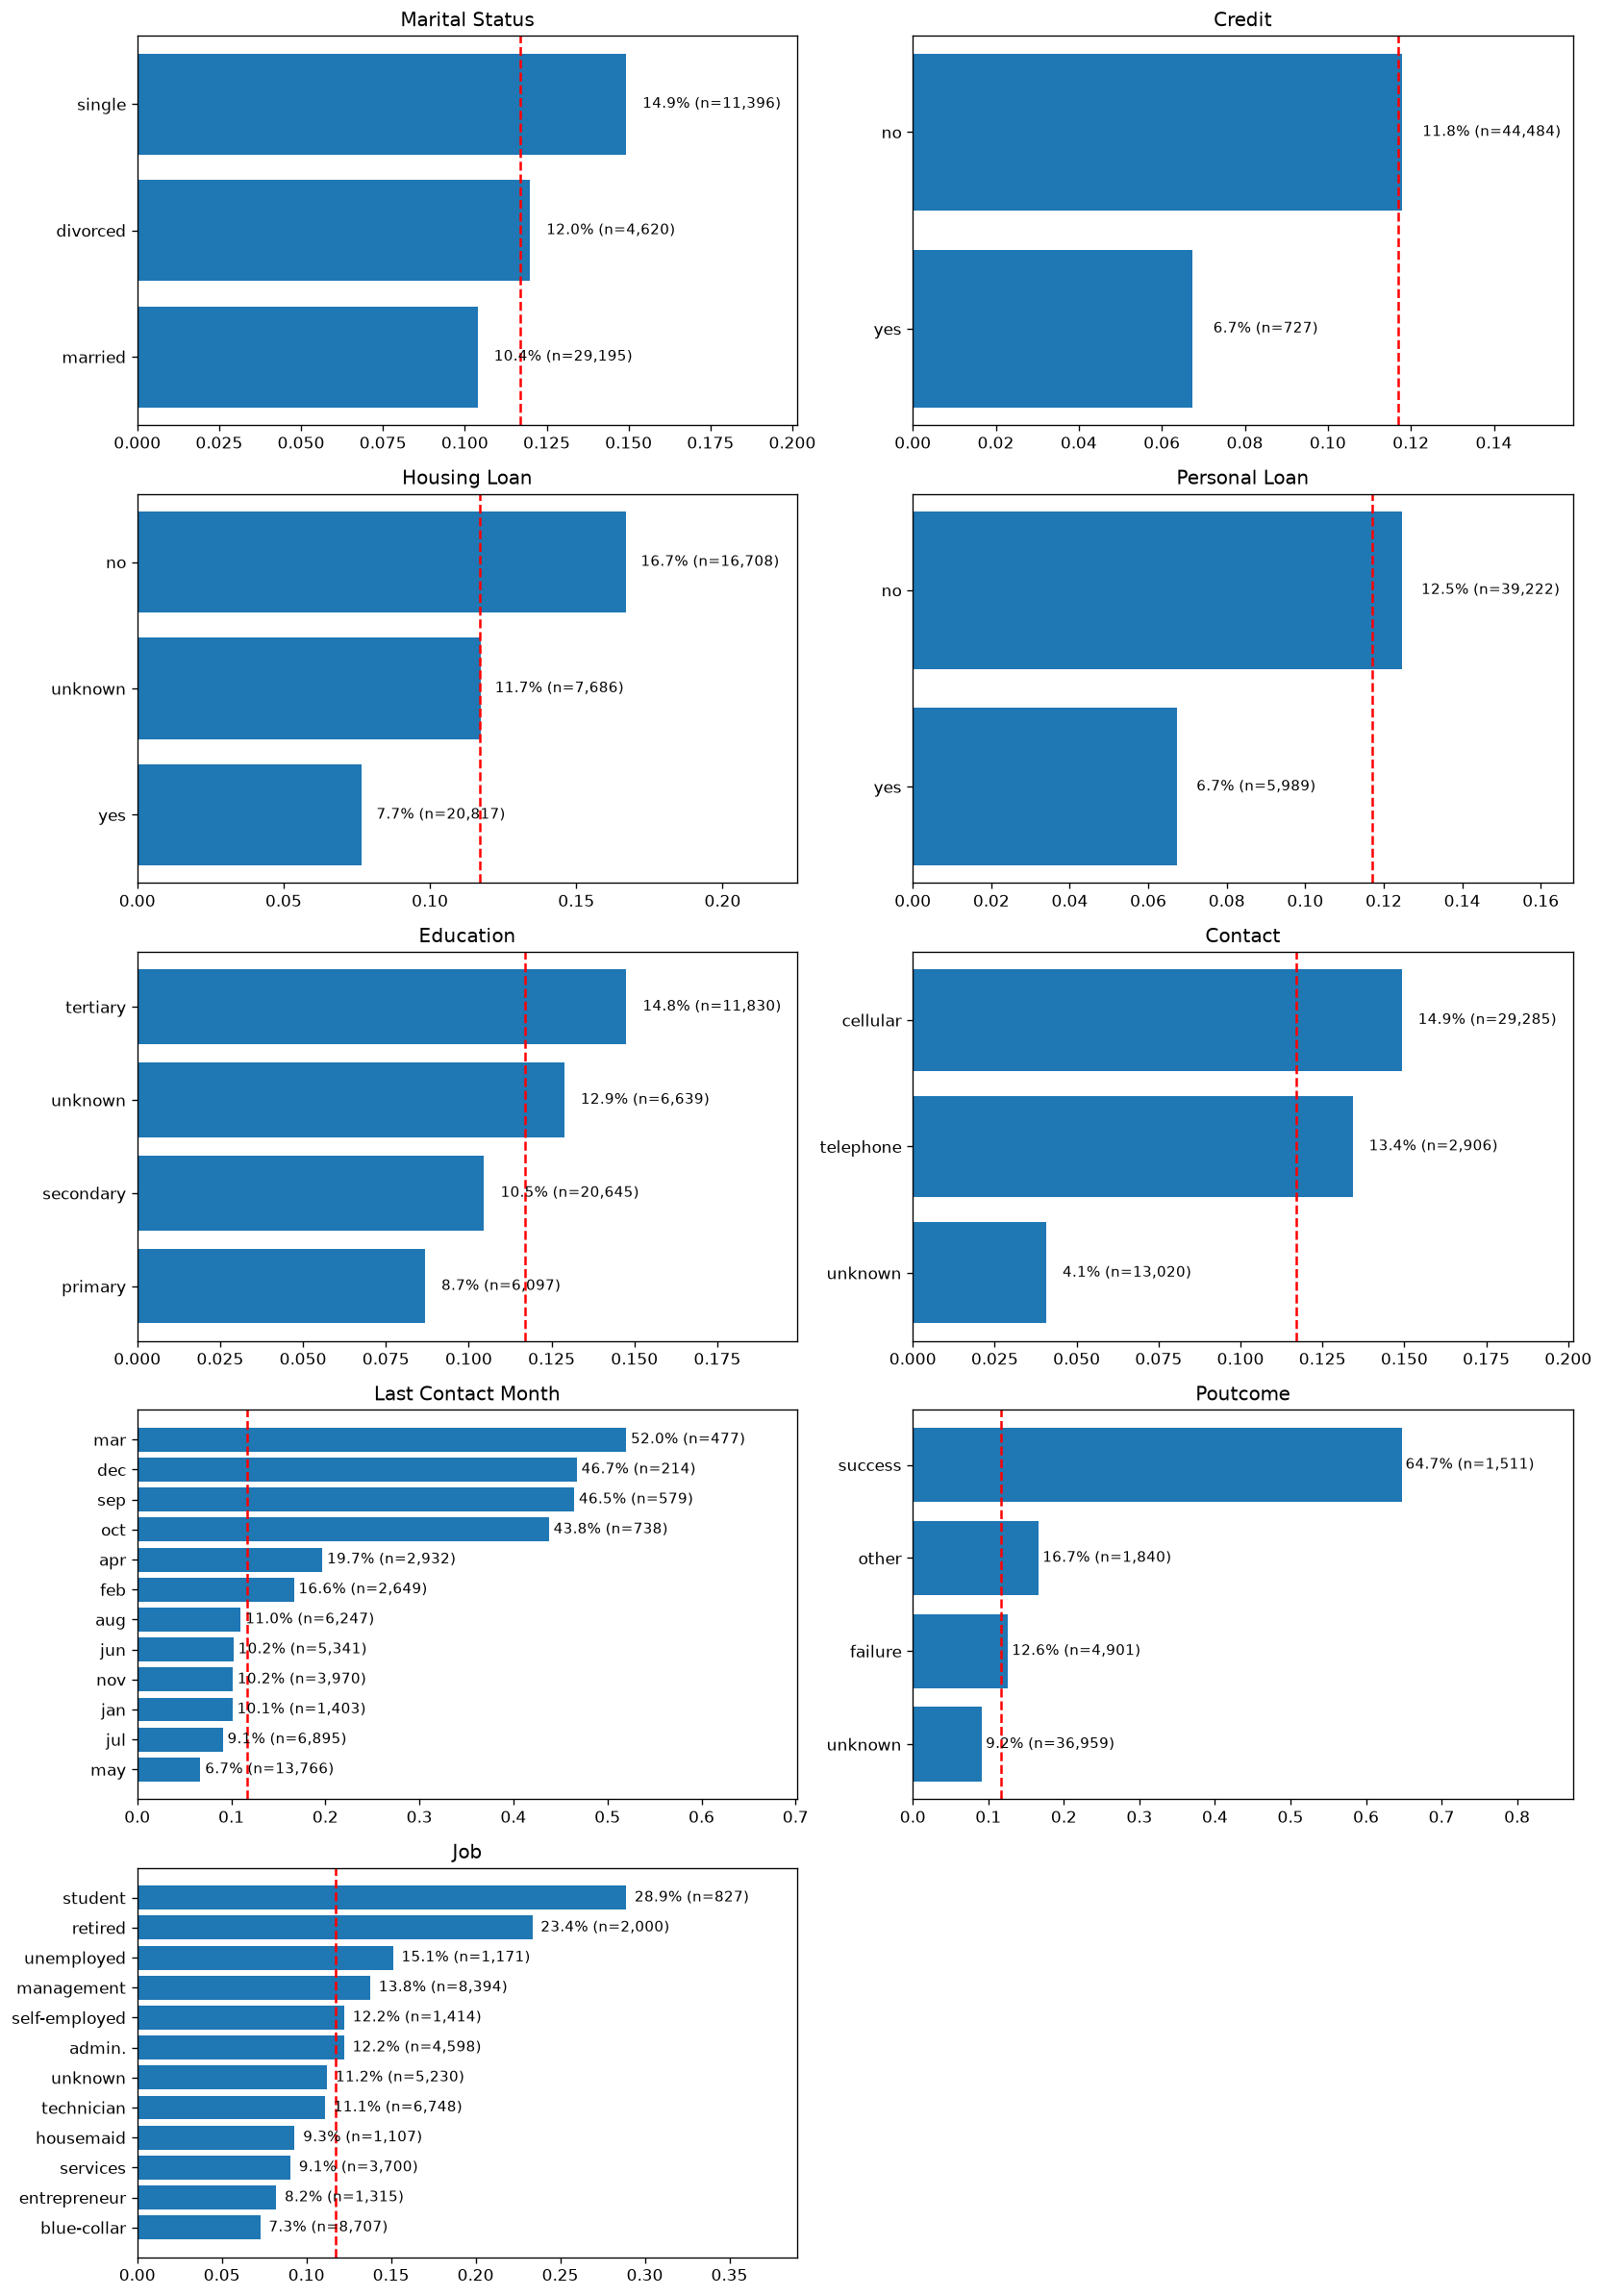

In [16]:
cols = ["Marital Status", "Credit", "Housing Loan", "Personal Loan", "Education", "Contact", "Last Contact Month", "Poutcome", "Job"]
tasa_general = df["Subscription"].mean()

n_cols = 2
n_rows = math.ceil(len(cols) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4 * n_rows), dpi=120)
axes = axes.flatten()

for ax, col in zip(axes, cols):
    resumen = df.groupby(col)["Subscription"].agg(tasa="mean", clientes="size").sort_values("tasa")

    ax.barh(resumen.index.astype(str), resumen["tasa"])
    ax.axvline(tasa_general, color="red", linestyle="--")

    for i, (tasa, n) in enumerate(zip(resumen["tasa"], resumen["clientes"])):
        ax.text(tasa + 0.005, i, f"{tasa:.1%} (n={n:,})", va="center", fontsize=9)

    ax.set_title(col)
    ax.set_xlim(0, resumen["tasa"].max() * 1.35)

for ax in axes[len(cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

### Conclusiones del análisis de variables categóricas

**Historial de contacto:** es el factor con mayor impacto. Los clientes cuya campaña anterior fue exitosa suscriben en un 64,7% de los casos, más de cinco veces la tasa general. En el otro extremo, los clientes contactados por primera vez (`unknown`) muestran la tasa más baja del grupo (9,2%). Incluso un resultado previo negativo (`failure`, 12,6%) supera a los clientes nuevos, lo que sugiere que el contacto previo, más allá de su resultado, favorece la suscripción.

**Endeudamiento:** los clientes con compromisos financieros suscriben considerablemente menos. Quienes tienen un préstamo hipotecario lo hacen en un 7,7% frente al 16,7% de quienes no lo tienen; en préstamos personales la relación es 6,7% frente a 12,5%, y en clientes con créditos en default, 6,7% frente a 11,8%.

**Perfil del cliente:** la tasa de suscripción crece con el nivel educativo (8,7% en primaria, 10,5% en secundaria y 14,8% en terciaria). Los clientes solteros (14,9%) suscriben más que los casados (10,4%). En cuanto a la actividad laboral, los estudiantes (28,9%), jubilados (23,4%) y desempleados (15,1%) suscriben muy por encima de la media. Al contrario, los operarios (7,3%), empresarios (8,2%) y trabajadores de servicios (9,1%) lo hacen muy por debajo.

**Medio de contacto:** los clientes con medio de contacto desconocido muestran una tasa muy inferior (4,1%) a la de quienes fueron contactados por celular (14,9%) o teléfono fijo (13,4%).

**Validación de la imputación:** en `Housing Loan`, la categoría `unknown` creada para los valores faltantes presenta una tasa intermedia (11,7%) entre `yes` y `no`, consistente con faltantes distribuidos al azar.

Los resultados de `Last Contact Month` nos llevan a hacer un doble click: graficamos la tasa de suscripción mes a mes, en orden cronológico.

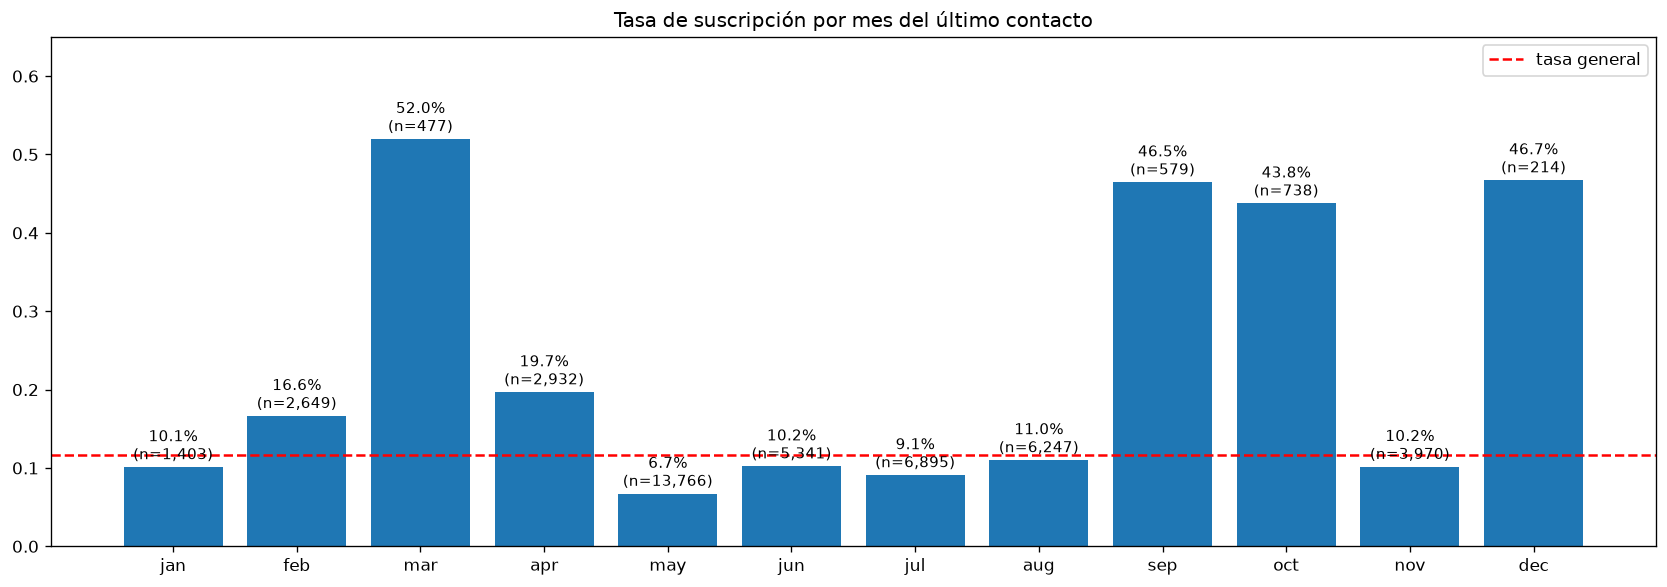

In [17]:
orden_meses = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]

resumen_mes = (df.groupby("Last Contact Month")["Subscription"]
                 .agg(tasa="mean", clientes="size")
                 .reindex(orden_meses))

fig, ax = plt.subplots(figsize=(14, 5), dpi=120)

ax.bar(resumen_mes.index, resumen_mes["tasa"])
ax.axhline(tasa_general, color="red", linestyle="--", label="tasa general")

for i, (tasa, n) in enumerate(zip(resumen_mes["tasa"], resumen_mes["clientes"])):
    ax.text(i, tasa + 0.01, f"{tasa:.1%}\n(n={n:,})", ha="center", fontsize=9)

ax.set_title("Tasa de suscripción por mes del último contacto")
ax.set_ylim(0, resumen_mes["tasa"].max() * 1.25)
ax.legend()

plt.tight_layout()
plt.show()

Viendo la tasa de suscripción por mes de esta forma, su evolución no parece responder a una estacionalidad sino más a un nivel de selectividad con los contactos realizados: los niveles más bajos de suscripción se ven en los meses de contacto más masivo (el peor mes es también el mes con más contactos, mayo) mientras que en los meses en los que menos se contactó se obtienen tasas que llegan a ser cuatro veces mayores a la media.

### `Poutcome` por mes: ¿se contactó a clientes más propensos a suscribir?

Si esta hipótesis es correcta, en los meses con menos contactos se debería haber contactado desproporcionadamente a clientes con un resultado exitoso en la campaña anterior (`Poutcome = success`), la categoría con mayor tasa de suscripción (64,7%).

Para verificarlo, analizamos la composición de `Poutcome` en cada mes.

In [18]:
cats_poutcome = ["success", "failure", "other", "unknown"]

# Composición de Poutcome en cada mes (% de los contactos del mes)
poutcome_mes = (pd.crosstab(df["Last Contact Month"], df["Poutcome"], normalize="index")
                  .reindex(orden_meses)[cats_poutcome])
poutcome_mes["clientes"] = resumen_mes["clientes"]
poutcome_mes["tasa"] = resumen_mes["tasa"]

formato = {col: "{:.1%}" for col in cats_poutcome + ["tasa"]}
formato["clientes"] = "{:,}"
poutcome_mes.style.format(formato).background_gradient(subset=["success"], cmap="Greens")

Poutcome,success,failure,other,unknown,clientes,tasa
Last Contact Month,,,,,,
jan,4.6%,20.6%,10.3%,64.5%,"1,403",10.1%
feb,5.4%,20.0%,9.5%,65.1%,"2,649",16.6%
mar,12.6%,15.7%,8.0%,63.7%,477,52.0%
apr,4.4%,25.1%,8.6%,61.9%,"2,932",19.7%
may,1.7%,12.3%,4.3%,81.7%,"13,766",6.7%
jun,2.2%,2.5%,1.3%,94.0%,"5,341",10.2%
jul,1.4%,1.6%,0.7%,96.3%,"6,895",9.1%
aug,3.3%,3.8%,1.4%,91.5%,"6,247",11.0%
sep,22.8%,20.7%,10.5%,45.9%,579,46.5%


Del análisis anterior surge que `Poutcome` es una de las variables más informativas del dataset: los clientes `success`, es decir, aquellos que suscribieron en una campaña anterior, vuelven a suscribir en el 64,7% de los casos. Es la característica del cliente más asociada a una potencial suscripción.

Al analizar cómo se distribuye esta variable a lo largo de los meses, se confirma la hipótesis planteada: **a menor cantidad de contactos, mayor selectividad y, en consecuencia, mayor tasa de suscripción**.

- En los meses de contacto más masivo (mayo, junio y julio), menos del 3% de los clientes contactados había suscripto en una campaña anterior.
- En los meses de mejor conversión (marzo, septiembre, octubre y diciembre), esa proporción se ubica entre el 12,6% y el 23,8%, es decir, entre 4 y 7 veces el promedio del dataset (3,3%).

## Análisis de variables continuas

### Distribución y asimetría

Antes de comparar las variables continuas según la suscripción, analizamos cómo se distribuye cada una. Usamos los valores observados (`df_raw`, sin imputar), para que las medianas imputadas no distorsionen los histogramas. Para cuantificar la asimetría calculamos el coeficiente de *skewness*: cerca de 0 indica una distribución simétrica, mientras que valores positivos indican una cola hacia la derecha (como referencia, se suele considerar muy asimétrica a una distribución con |skew| > 1).

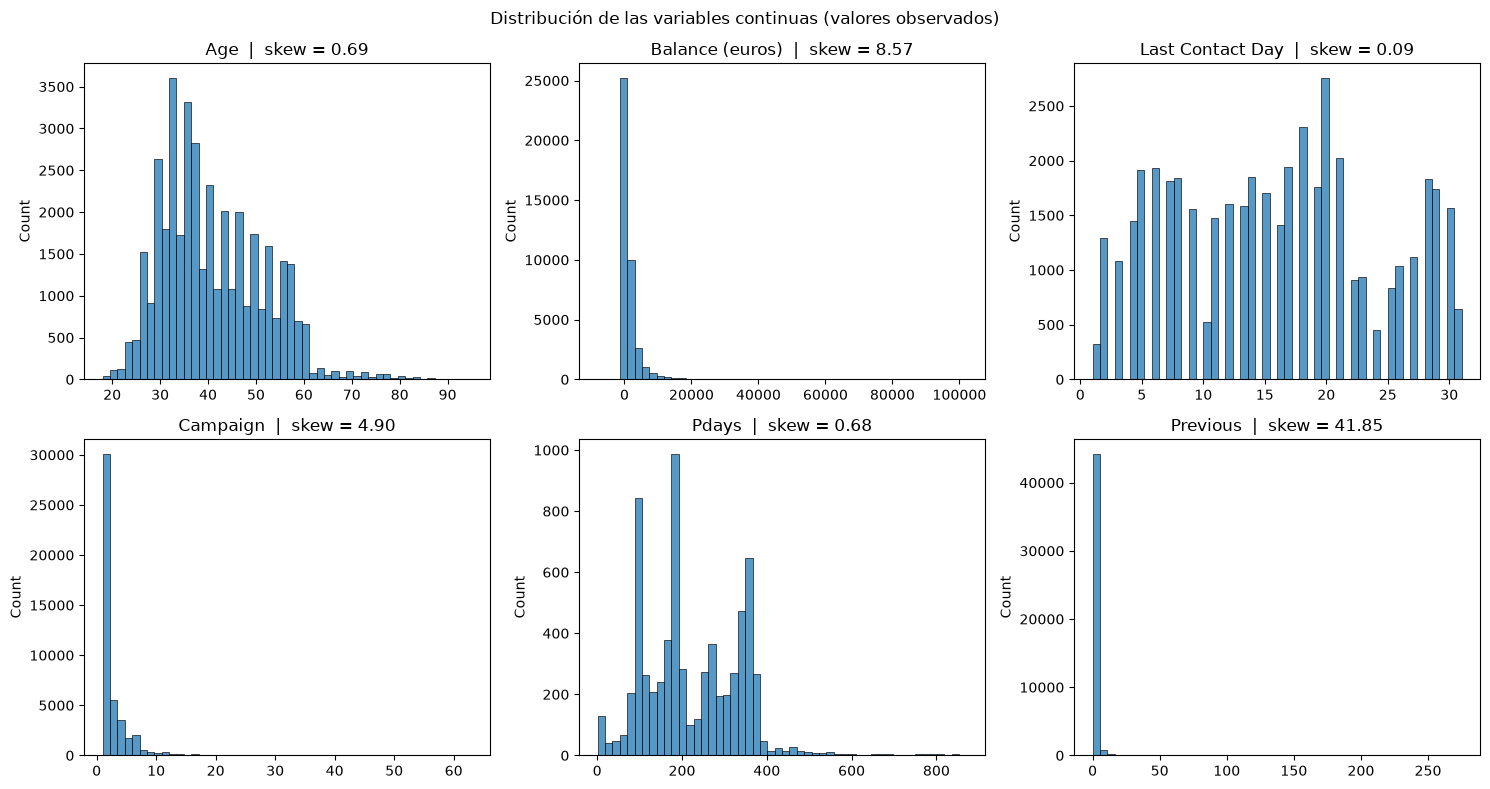

In [19]:
continuas = ["Age", "Balance (euros)", "Last Contact Day", "Campaign", "Pdays", "Previous"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flatten(), continuas):
    datos = df_raw[col].dropna()
    # En Pdays, -1 es un código ("nunca contactado"), no una cantidad de días: lo excluimos
    if col == "Pdays":
        datos = datos[datos != -1]
    sns.histplot(datos, bins=50, ax=ax)
    ax.set_title(f"{col}  |  skew = {skew(datos):.2f}")
    ax.set_xlabel("")

fig.suptitle("Distribución de las variables continuas (valores observados)")
plt.tight_layout()
plt.show()

`Balance (euros)`, `Campaign` y `Previous` presentan una asimetría muy fuerte: casi todos los valores se concentran cerca del mínimo y una cola larga se extiende hacia valores extremos. Así, los histogramas aportan poca información. Como vimos en clase, en estos casos conviene cambiar la escala aplicando una transformación logarítmica, `log(1 + x)`.

Dos aclaraciones:

- `Balance (euros)` tiene valores negativos, para los que el logaritmo no está definido. Usamos la variante con signo, `sign(x) · log(1 + |x|)`, que conserva el signo y comprime la magnitud.
- En `Previous`, el 81,7% de los valores es 0. Para ver la forma de la distribución, graficamos solo los clientes contactados previamente (`Previous > 0`).

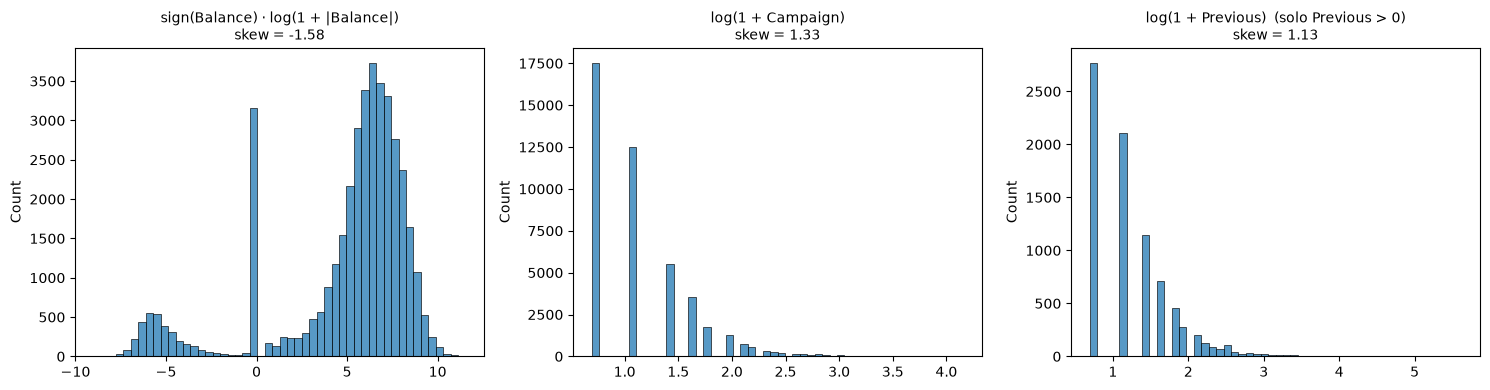

In [20]:
balance = df_raw["Balance (euros)"].dropna()
previous_pos = df_raw.loc[df_raw["Previous"] > 0, "Previous"]

transformadas = {
    "sign(Balance) · log(1 + |Balance|)": np.sign(balance) * np.log1p(np.abs(balance)),
    "log(1 + Campaign)": np.log1p(df_raw["Campaign"]),
    "log(1 + Previous)  (solo Previous > 0)": np.log1p(previous_pos),
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (nombre, datos) in zip(axes, transformadas.items()):
    sns.histplot(datos, bins=50, ax=ax)
    ax.set_title(f"{nombre}\nskew = {skew(datos):.2f}", fontsize=10)
    ax.set_xlabel("")

plt.tight_layout()
plt.show()

La transformación logarítmica reduce notablemente la asimetría de `Campaign` y `Previous` y permite ver la forma de sus distribuciones. En `Balance (euros)` se distinguen dos grupos: la gran mayoría de saldos positivos y un grupo más chico de saldos negativos (el 7,4% de los clientes con dato informado), separados por un pico en 0 (el skew negativo resultante refleja esa cola de saldos negativos). Estas transformaciones son candidatas a aplicarse en la etapa de modelado, sobre todo para modelos sensibles a la escala de las variables.

### Outliers

Para cuantificar los valores atípicos usamos el mismo criterio que el boxplot: se considera *outlier* a todo valor por debajo de Q1 - 1,5·IQR o por encima de Q3 + 1,5·IQR, donde IQR = Q3 - Q1 es el rango intercuartil. Como referencia, agregamos también el percentil 99.

In [21]:
filas_outliers = []

for col in continuas:
    datos = df_raw[col].dropna()
    if col == "Pdays":
        datos = datos[datos != -1]
    q1, q3 = datos.quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_outliers = ((datos < lim_inf) | (datos > lim_sup)).sum()
    filas_outliers.append({
        "variable": col,
        "Q1": q1,
        "Q3": q3,
        "lím. inferior": lim_inf,
        "lím. superior": lim_sup,
        "outliers": n_outliers,
        "% outliers": round(100 * n_outliers / len(datos), 1),
        "percentil 99": datos.quantile(0.99),
        "máximo": datos.max(),
    })

tabla_outliers = pd.DataFrame(filas_outliers).set_index("variable").round(1)
tabla_outliers

,Q1,Q3,lím. inferior,lím. superior,outliers,% outliers,percentil 99,máximo
variable,,,,,,,,
Age,33.0,48.0,10.5,70.5,440,1.1,71.0,95.0
Balance (euros),72.0,1425.8,-1958.6,3456.4,4217,10.5,13312.4,102127.0
Last Contact Day,8.0,21.0,-11.5,40.5,0,0.0,31.0,31.0
Campaign,1.0,3.0,-2.0,6.0,3064,6.8,16.0,63.0
Pdays,132.0,327.0,-160.5,619.5,38,0.6,522.8,871.0
Previous,0.0,0.0,0.0,0.0,8257,18.3,8.9,275.0


**Decisión: no eliminamos outliers.** Los motivos:

- **Son valores plausibles, no errores de carga.** Saldos negativos (cuentas en descubierto), saldos altos o clientes llamados muchas veces son situaciones reales del negocio. Eliminarlos implicaría descartar, por ejemplo, el 10,5% de los registros de `Balance (euros)`.
- **En `Previous`, el criterio IQR no es aplicable.** Como Q1 = Q3 = 0, el rango intercuartil es 0 y todo cliente contactado previamente (18,3%) queda marcado como outlier. Ese es justamente el grupo más informativo del dataset: allí están los clientes con `Poutcome = success`. Eliminarlos sería perder la señal más fuerte.
- **El caso extremo es aislado.** El único valor claramente sospechoso es `Previous = 275`, muy por encima del siguiente (58) y del percentil 99 (≈9). Al tratarse de un solo registro, su impacto es despreciable.

En lugar de eliminar valores, el tratamiento se resuelve en el modelado: para los modelos sensibles a la escala (regresión logística, KNN, SVM) y para PCA, conviene aplicar las transformaciones logarítmicas anteriores y estandarizar. Los modelos basados en árboles, en cambio, no se ven afectados por los outliers.

### Distribución según suscripción

El siguiente paso es analizar cómo se distribuyen las variables continuas **entre los casos donde se da la suscripción y en los que no**.

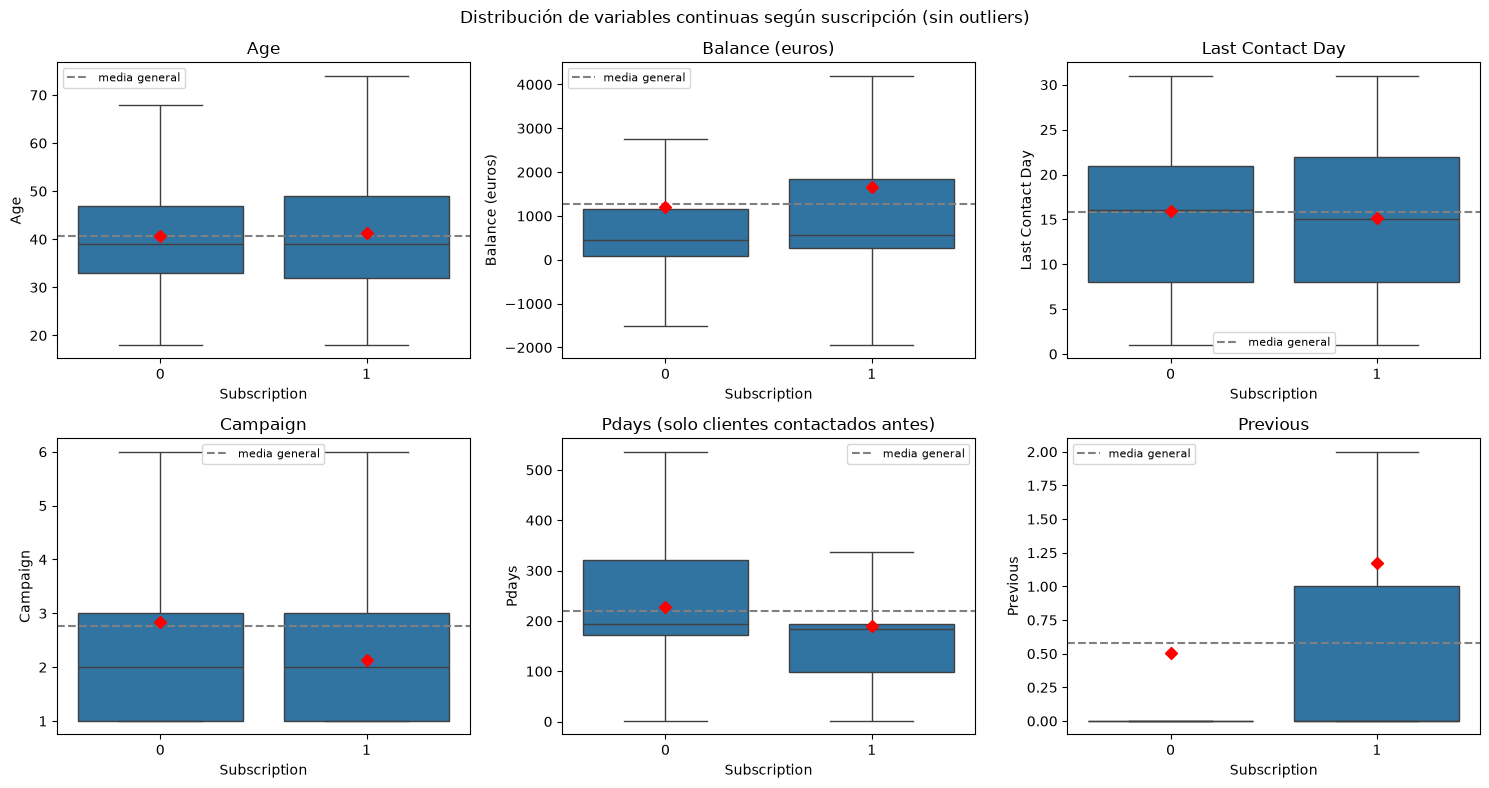

In [22]:
target = "Subscription"
continuas = ["Age", "Balance (euros)", "Last Contact Day", "Campaign", "Pdays", "Previous"]

n = len(continuas)
ncols = 3
nrows = -(-n // ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
axes = axes.flatten()

for ax, col in zip(axes, continuas):
    # En Pdays, -1 es un código ("nunca contactado"), no una cantidad de días: lo excluimos
    datos = df[df["Pdays"] != -1] if col == "Pdays" else df
    sns.boxplot(data=datos, x=target, y=col, showmeans=True, showfliers=False,
                meanprops={"marker": "D", "markerfacecolor": "red", "markeredgecolor": "red"},
                ax=ax)
    ax.axhline(datos[col].mean(), color="gray", linestyle="--", label="media general")
    ax.set_title(f"{col} (solo clientes contactados antes)" if col == "Pdays" else col)
    ax.legend(fontsize=8)

for ax in axes[n:]:
    ax.set_visible(False)

fig.suptitle("Distribución de variables continuas según suscripción (sin outliers)")
plt.tight_layout()
plt.show()

### Conclusiones del análisis de variables continuas

En comparación con las variables categóricas, las continuas muestran un **poder discriminante bajo**: en la mayoría de los casos, las distribuciones de quienes suscriben y quienes no se superponen ampliamente.

**Historial de contacto (Previous y Pdays):** es la señal más clara. Entre quienes no suscriben, la caja de `Previous` está colapsada en 0, es decir, la gran mayoría nunca había sido contactada en campañas anteriores; entre quienes suscriben, en cambio, la caja se extiende hasta 1 y la media duplica a la de quienes no suscriben (~1,2 frente a ~0,5). Además, entre los clientes contactados previamente, quienes suscriben registran contactos más recientes: el 75% fue contactado hace menos de ~200 días, mientras que entre quienes no suscriben una cuarta parte supera los ~320 días (medias de ~190 y ~228 días, respectivamente). Esta señal es en buena medida la misma que captura `Poutcome`.

**Campaign:** la mediana es la misma en ambos grupos (2 llamadas), pero quienes suscriben recibieron en promedio menos llamadas (~2,1 frente a ~2,8). Esta diferencia, sin embargo, no debe interpretarse como que insistir sea contraproducente: está sesgada por la propia dinámica de la campaña. El banco deja de llamar a quien acepta, por lo que los valores altos de `Campaign` se componen, por construcción, de clientes que rechazaron la oferta. Lo que sí sugiere el gráfico es que la mayoría de las suscripciones se concentra en las primeras llamadas, por lo que insistir no parece sumar demasiado.

**Balance:** quienes suscriben presentan saldos algo mayores (media de ~1.650 € frente a ~1.200 €, y una caja desplazada hacia arriba), una diferencia moderada y coherente con la necesidad de contar con fondos disponibles para un plazo fijo.

**Age:** no se observan diferencias en el centro de la distribución (mediana de ~39 años en ambos grupos), aunque la caja de quienes suscriben es algo más amplia. Esto es consistente con el análisis categórico, donde estudiantes y jubilados, ubicados en los extremos de edad, suscriben muy por encima de la media.

**Last Contact Day:** las distribuciones son prácticamente idénticas, por lo que no aporta información sobre la suscripción.

## Correlación lineal entre variables numéricas

Por último, calculamos la matriz de correlación de Pearson entre las variables continuas y el target. Como `Subscription` es binaria (0/1), su correlación de Pearson con una variable continua equivale a la correlación punto-biserial y mide la asociación lineal entre ambas. Recordemos que la correlación solo capta relaciones lineales, y que correlación no implica causalidad.

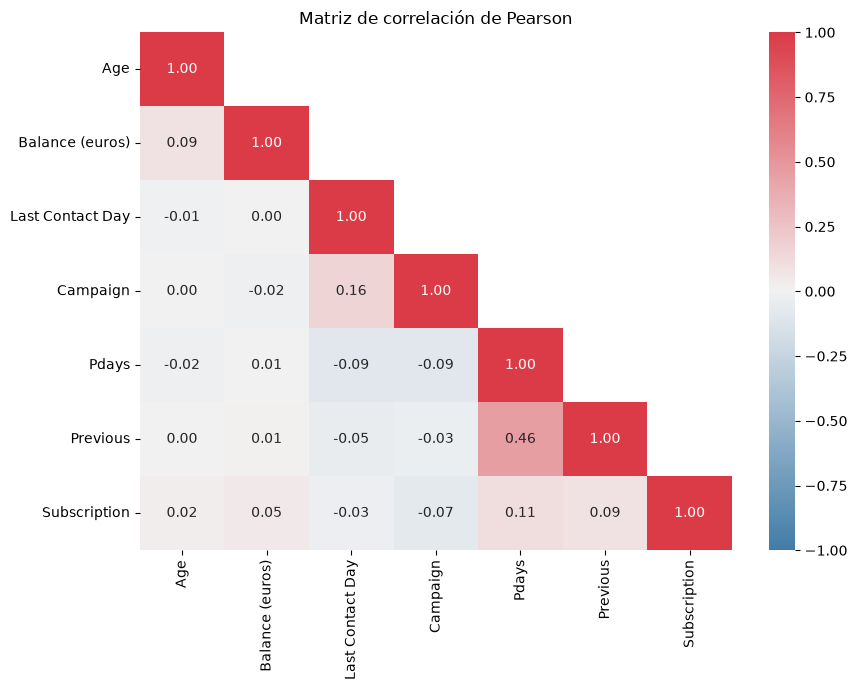

In [23]:
corr = df[continuas + ["Subscription"]].corr()
mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)  # ocultamos el triángulo superior (redundante)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", vmin=-1, vmax=1,
            cmap=sns.diverging_palette(240, 10, as_cmap=True), ax=ax)
ax.set_title("Matriz de correlación de Pearson")
plt.tight_layout()
plt.show()

**Conclusiones de la matriz de correlación:**

- **Correlaciones débiles con el target:** la correlación más alta con `Subscription` es de apenas 0,11 (`Pdays`), seguida por `Previous` (0,09) y `Campaign` (-0,07). Esto confirma lo observado en los boxplots: individualmente, las variables continuas tienen poco poder discriminante, y la señal está más en las categóricas (sobre todo `Poutcome`).
- **Redundancia entre Pdays y Previous:** es el único par con una correlación moderada (0,46). Tiene sentido: ambas miden el historial de contacto. Hay que tener en cuenta que en `Pdays` la mayoría de los valores es el código -1, por lo que esta correlación refleja sobre todo la distinción entre clientes contactados y no contactados, que es la misma información que contiene `Poutcome`.
- **Sin multicolinealidad relevante:** el resto de los pares tiene correlaciones cercanas a 0. Para la etapa de reducción de dimensionalidad, esto anticipa que PCA no podrá comprimir mucho la información de las variables numéricas, ya que comparten poca varianza entre sí.

## Conclusiones generales del EDA

### Hallazgos principales

1. **Calidad de los datos:** no hay registros duplicados. El 71,7% de las filas tiene al menos un nulo, pero los faltantes están dispersos y no se asocian con la suscripción, por lo que los imputamos en lugar de eliminar filas.
2. **El target está desbalanceado:** solo el 11,7% de los clientes contactados suscribe.
3. **El historial con el banco es el factor más determinante:** los clientes que suscribieron en una campaña anterior (`Poutcome = success`) vuelven a hacerlo en el 64,7% de los casos, y haber sido contactado previamente se asocia con mayor suscripción, como muestran también `Previous` y `Pdays`.
4. **El endeudamiento reduce la propensión a suscribir:** los clientes con préstamo hipotecario, préstamo personal o créditos en default suscriben considerablemente menos.
5. **El perfil del cliente importa:** estudiantes, jubilados, clientes con educación terciaria y solteros suscriben por encima de la media, y quienes suscriben presentan saldos algo mayores.
6. **El momento del contacto refleja la estrategia de la campaña más que una estacionalidad:** los meses de contacto masivo muestran las tasas más bajas, mientras que en los meses de menor actividad se contactó desproporcionadamente a clientes con historial exitoso y las tasas son muy superiores a la media.
7. **Las variables continuas son muy asimétricas y aportan poca señal lineal:** `Balance (euros)`, `Campaign` y `Previous` tienen colas largas y outliers (que conservamos por ser valores reales), y ninguna variable continua supera una correlación de 0,11 con el target.

### Implicancias para el modelado

- **Variables descartadas:** `Last Contact Duration`, por *data leakage*.
- **Variables a tratar con cautela:** `Campaign`, cuya relación con el target está sesgada por la dinámica de la campaña (el banco deja de llamar a quien acepta), y `Last Contact Month`, que refleja más la etapa de la campaña que una característica del cliente y podría no generalizar a campañas futuras.
- **Variables con mayor poder predictivo esperado:** `Poutcome`, `Previous`, `Pdays`, `Housing Loan` y `Job`. Dado que `Poutcome`, `Previous` y `Pdays` capturan en buena medida la misma información, conviene evaluar su redundancia.
- **Evaluación:** por el desbalance del target, utilizar métricas centradas en la clase minoritaria (precision, recall, F1) en lugar de accuracy, y realizar una partición train/test estratificada.
- **Escalado y outliers:** para modelos sensibles a la escala (regresión logística, KNN, SVM) y para PCA, aplicar `log(1 + x)` a `Campaign` y `Previous`, la variante con signo a `Balance (euros)`, y estandarizar. Los árboles no requieren estas transformaciones.
- **Reducción de dimensionalidad:** como las variables numéricas están poco correlacionadas entre sí, PCA no debería concentrar mucha varianza en pocas componentes. Conviene analizar la varianza explicada acumulada para elegir la cantidad de componentes.
- **Imputación:** en esta etapa, las medianas y modas se calcularon sobre el dataset completo. Para el modelado, deben calcularse únicamente sobre el conjunto de entrenamiento, para evitar filtrar información del conjunto de test.